# 01 — Auditoria de jurisprudência

Auditoria dos **19 arquivos no escopo ativo**: JSONL do TRT-13, JSON aninhado do TST e 17 arquivos Parquet. A identificação dos tribunais é feita pelos campos disponíveis nos registros, não pela simples menção a um tribunal no texto nem pelos sufixos de download dos arquivos.

Esta etapa cobre inventário, integridade de leitura, quantidade de registros, features e tipos, completude, texto disponível, datas, duplicatas internas e entre arquivos, sinais de dados pessoais e rastreabilidade. **Não altera as fontes, não faz deduplicação destrutiva, não treina modelos e não indexa o conteúdo.**

## Método e limites

- Leitura integral dos registros legíveis em lotes, com checkpoints por arquivo e hashes SHA-256. Falhas em um arquivo não impedem a análise dos demais.
- Originais preservados em Downloads; não foi feita uma cópia de vários gigabytes para o Git. O inventário registra caminho, tamanho e hash. Ao transferir os originais para armazenamento definitivo, preserve os bytes e os manifestos.
- Estatísticas de presença, tipos, contagens e tamanhos são integrais nos registros lidos. Cardinalidade de valores é limitada aos primeiros 2.000 hashes distintos por feature e identificada como limite inferior quando o limite é atingido.
- Descrição das features não confirma seu significado jurídico. Datas, referências e campos de coleta exigem conferência do produtor.
- Nenhum texto de decisão, nome de parte, CPF ou e-mail é mostrado nos relatórios. A triagem de dados pessoais não é anonimização nem comprovação de conformidade jurídica.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython.core.display import Markdown

ROOT_JUR = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (p/'src/jurisprudencia/audit.py').is_file()), None)
if ROOT_JUR is None:
    raise FileNotFoundError('Raiz do projeto não encontrada.')
if str(ROOT_JUR) not in sys.path:
    sys.path.insert(0, str(ROOT_JUR))
from src.jurisprudencia import audit, report
EXECUTAR_AUDITORIA = False  # True para reler fontes, validar hashes e retomar checkpoints.
PASTA_ORIGINAIS = Path.home()/'Downloads'
if EXECUTAR_AUDITORIA:
    REPORT_JUR, resumo_jur, perfis_jur = audit.run(ROOT_JUR, [PASTA_ORIGINAIS/n for n in audit.FILES])
else:
    REPORT_JUR, resumo_jur, perfis_jur = report.load(ROOT_JUR)
print('Relatórios:', REPORT_JUR)
print('Modo: leitura de auditoria executada' if not EXECUTAR_AUDITORIA else 'Auditoria executada/retomada')
# Escopo ativo do notebook 01
from src.jurisprudencia import presentation
resumo_jur,perfis_jur,REPORT_JUR_VIEW=presentation.audit_scope(ROOT_JUR,REPORT_JUR,resumo_jur,perfis_jur)


Relatórios: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\jurisprudencia\auditoria\71714343f9fd896da188fc14ed120ae9b8343b744455f40aba12edfb2536242f\772354ed79c2da034628522bf7705bf82f6b9414f2fa9197fe0f1743696e4d27
Modo: leitura de auditoria executada


## 1. Inventário, integridade e volume

Quantidade de arquivos não equivale a quantidade de decisões. A mesma fonte pode estar distribuída em shards ou repetida em formatos diferentes. Arquivos de bytes idênticos são sinalizados por hash; registros repetidos são medidos separadamente.

**Arquivo ilegível não significa dataset com zero registros.** A contagem lida nesse caso é zero e a quantidade real permanece desconhecida. Não inferimos a quantidade a partir de outro shard. Assinatura PAR1 sozinha não comprova que um Parquet esteja íntegro.

In [2]:
df_inventario_jur = pd.read_csv(REPORT_JUR/'inventario_arquivos.csv', keep_default_na=False)
df_inventario_jur=df_inventario_jur[df_inventario_jur['arquivo'].isin([p['arquivo'] for p in perfis_jur])].copy()
display(pd.Series({k:v for k,v in resumo_jur.items() if not isinstance(v,(dict,list))},name='resultado').to_frame())
display(df_inventario_jur)
problemas_jur = df_inventario_jur[df_inventario_jur['status'].ne('concluido')]
display(problemas_jur[['arquivo','status','registros_declarados_metadata','registros_lidos','tipo_erro']])

,resultado
protocolo,jurisprudencia-auditoria-v2
inventario_sha256,71714343f9fd896da188fc14ed120ae9b8343b744455f4...
codigo_auditor_sha256,772354ed79c2da034628522bf7705bf82f6b9414f2fa91...
gerado_em_utc,2026-11-13T21:36:34.680827+00:00
data_referencia,2026-11-13
arquivos_recebidos,19
arquivos_presentes,20
bytes_recebidos,2960623829
arquivos_concluidos,19
arquivos_com_falha_ou_leitura_parcial,0


,arquivo_id,arquivo,formato,bytes,sha256,status,registros_declarados_metadata,registros_lidos,features_raiz,features_incluindo_aninhadas,tribunais,tipo_erro
0,f01,jurisprudencia_trt13.jsonl,jsonl,41527321,88efe90ce20b880b75c04a9a0f3b80c2a7892139d6a310...,concluido,,15730,18,18,"{""TRT-13"": 15730}",
1,f02,jurisprudencias_tst.json,json,123669364,4eb6de499a97519c8d5cbd6df1268d621fa9a279b75541...,concluido,,10000,2,60,"{""TST"": 10000}",
2,f03,train-00001.parquet,parquet,225364323,ff0d36929229a52412fdc1e4103c47b42ab8264b2f0099...,concluido,50000,50000,17,17,"{""STF"": 49848, ""não identificado"": 152}",
3,f04,train-00000.parquet,parquet,432647327,c6a05e79ebc8f7134d2e0bb7156991ecaabdc89c4b25df...,concluido,50000,50000,17,17,"{""STF"": 48463, ""não identificado"": 1537}",
5,f06,train-00005.parquet,parquet,296881832,0cbf1b748a88318e20d76b76abe0a4437c54b7b18b7752...,concluido,50000,50000,17,17,"{""STF"": 50000}",
6,f07,part-00000.parquet,parquet,1752046,bc25c4a23b4ea11a8d22d3e67b01785b555e2f2e3e7184...,concluido,366,366,25,25,"{""TRT-17"": 366}",
7,f08,part-00000 (1).parquet,parquet,84077084,ca4af25f1cd8e4b9a122f5b1439ec5a59a3de26dc21947...,concluido,18780,18780,25,25,"{""TRT-17"": 18780}",
8,f09,part-00000 (3).parquet,parquet,5194941,9208e5339fe06e6236530ab54f99d08847857df3391316...,concluido,1114,1114,25,25,"{""TRT-17"": 1114}",
9,f10,part-00000 (2).parquet,parquet,81127112,b80163341d97b287eb4decbd43cf93b48bc94eb6612fd6...,concluido,17714,17714,25,25,"{""TRT-17"": 17714}",
10,f11,part-00000 (4).parquet,parquet,23779,235a4f386732e682ea8940c2e8b6969bb3a67d4d46da11...,concluido,1,1,25,25,"{""TRT-17"": 1}",


,arquivo,status,registros_declarados_metadata,registros_lidos,tipo_erro


## 2. Datasets e tribunais identificados

Prioridade: `tribunal`, `court`, `registro.orgao.sigla` e `registro.orgao.nome`. O número de um TRT é padronizado como TRT-10, TRT-13 etc. No JSON do TST, a identificação pode estar dentro do objeto `registro.orgao`. Apenas o nome de um arquivo constitui hipótese, registrada separadamente.

O TRT de origem de um processo citado em decisão do TST ou STF não muda o tribunal julgador do documento. Também não classificamos um documento pelo nome de tribunal mencionado no corpo do texto.

Os nomes genéricos `part-00000` e os sufixos `(1)`, `(2)` não identificam o repositório original do dataset. Cada arquivo permanece individualizado.

In [3]:
df_tribunais_jur = pd.read_csv(REPORT_JUR/'tribunais.csv')
display(df_tribunais_jur)
linhas_tribunais_jur = [{'arquivo_id':p['arquivo_id'],'arquivo':p['arquivo'], 'tribunal':t,
    'registros':n, 'evidencias':json.dumps(p.get('metodos_identificacao',{}),ensure_ascii=False)}
    for p in perfis_jur for t,n in p['tribunais'].items()]
display(pd.DataFrame(linhas_tribunais_jur))

,tribunal,registros_lidos
0,STF,148311
1,TRT-10,30486
2,TRT-13,15730
3,TRT-17,37975
4,TST,375681
5,não identificado,1689


,arquivo_id,arquivo,tribunal,registros,evidencias
0,f01,jurisprudencia_trt13.jsonl,TRT-13,15730,"{""campo_estruturado:tribunal"": 15730}"
1,f02,jurisprudencias_tst.json,TST,10000,"{""campo_estruturado:registro.orgao.sigla"": 10000}"
2,f03,train-00001.parquet,STF,49848,"{""campo_estruturado:tribunal"": 49848, ""sem_evi..."
3,f03,train-00001.parquet,não identificado,152,"{""campo_estruturado:tribunal"": 49848, ""sem_evi..."
4,f04,train-00000.parquet,STF,48463,"{""campo_estruturado:tribunal"": 48463, ""sem_evi..."
5,f04,train-00000.parquet,não identificado,1537,"{""campo_estruturado:tribunal"": 48463, ""sem_evi..."
6,f06,train-00005.parquet,STF,50000,"{""campo_estruturado:tribunal"": 50000}"
7,f07,part-00000.parquet,TRT-17,366,"{""campo_estruturado:tribunal"": 366}"
8,f08,part-00000 (1).parquet,TRT-17,18780,"{""campo_estruturado:tribunal"": 18780}"
9,f09,part-00000 (3).parquet,TRT-17,1114,"{""campo_estruturado:tribunal"": 1114}"


## 3. Features, tipos e completude

O dicionário informa todas as colunas e caminhos aninhados observados, tipos, preenchidos, chave ausente, nulo, vazio, cardinalidade observada e maior tamanho em caracteres. Contêineres como `registro` e folhas como `registro.ementa` são distinguidos; a contagem com aninhamentos não deve ser confundida com número de colunas físicas.

`data_json` e `metadata_extra_json` são strings nesta etapa. A auditoria não assume que seus conteúdos internos tenham sido validados ou normalizados. Zero e `False` contam como preenchidos; nulo, string só com espaços e contêiner vazio são distinguidos de chave ausente.

In [4]:
report.enrich_dictionary(REPORT_JUR)
display(pd.DataFrame(report.schema_families(REPORT_JUR, perfis_jur)))
print('Famílias agrupam somente esquemas compatíveis; não comprovam que arquivos vieram do mesmo dataset ou repositório.')
df_features_jur = pd.read_csv(REPORT_JUR/'dicionario_features.csv')
display(df_inventario_jur[['arquivo','features_raiz','features_incluindo_aninhadas']])
display(df_features_jur.sort_values(['arquivo','feature']))
print('Dicionário completo:', REPORT_JUR/'dicionario_features.csv')
categorias_jur = [{'arquivo':p['arquivo'],'feature':campo,'valor_declarado':valor,'ocorrencias':n}
    for p in perfis_jur for campo,contagem in p.get('categorias',{}).items() for valor,n in contagem.items()]
display(pd.DataFrame(categorias_jur).head(50))
print('Categorias: até 30 valores mais frequentes por campo seguro; não são exemplos de texto ou de partes.')

Famílias agrupam somente esquemas compatíveis; não comprovam que arquivos vieram do mesmo dataset ou repositório.
Dicionário completo: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\jurisprudencia\auditoria\71714343f9fd896da188fc14ed120ae9b8343b744455f40aba12edfb2536242f\772354ed79c2da034628522bf7705bf82f6b9414f2fa9197fe0f1743696e4d27\dicionario_features.csv
Categorias: até 30 valores mais frequentes por campo seguro; não são exemplos de texto ou de partes.


,arquivo_id,arquivo,familia_estrutural,features_raiz,registros_lidos,status
0,f01,jurisprudencia_trt13.jsonl,eb3ee2688c85,18,15730,concluido
1,f02,jurisprudencias_tst.json,f3b2e03cea5b,2,10000,concluido
2,f03,train-00001.parquet,217d6aa545f0,17,50000,concluido
3,f04,train-00000.parquet,217d6aa545f0,17,50000,concluido
4,f06,train-00005.parquet,217d6aa545f0,17,50000,concluido
5,f07,part-00000.parquet,4fc7b25799b1,25,366,concluido
6,f08,part-00000 (1).parquet,4fc7b25799b1,25,18780,concluido
7,f09,part-00000 (3).parquet,4fc7b25799b1,25,1114,concluido
8,f10,part-00000 (2).parquet,4fc7b25799b1,25,17714,concluido
9,f11,part-00000 (4).parquet,4fc7b25799b1,25,1,concluido


,arquivo,features_raiz,features_incluindo_aninhadas
0,jurisprudencia_trt13.jsonl,18,18
1,jurisprudencias_tst.json,2,60
2,train-00001.parquet,17,17
3,train-00000.parquet,17,17
5,train-00005.parquet,17,17
6,part-00000.parquet,25,25
7,part-00000 (1).parquet,25,25
8,part-00000 (3).parquet,25,25
9,part-00000 (2).parquet,25,25
10,part-00000 (4).parquet,25,25


,arquivo,feature,nivel,tipos_observados,registros,campo_ausente,valor_nulo,vazio_nao_nulo,preenchidos,percentual_ausente_nulo_vazio,cardinalidade_observada,cardinalidade_modo,max_caracteres,descricao_tecnica
0,jurisprudencia_trt13.jsonl,ano_assinatura,raiz,"{""int"": 15730}",15730,0,0,0,15730,0.000000,2,exata,0,Ano de assinatura informado pelo produtor; cam...
1,jurisprudencia_trt13.jsonl,arquivo_fonte,raiz,"{""str"": 15730}",15730,0,0,0,15730,0.000000,1,exata,24,Nome da fonte anterior informado pelo produtor...
2,jurisprudencia_trt13.jsonl,classe,raiz,"{""str"": 15730}",15730,0,0,130,15600,0.008264,25,exata,10,Classe processual declarada; padronização de c...
3,jurisprudencia_trt13.jsonl,data_assinatura,raiz,"{""str"": 15730}",15730,0,0,0,15730,0.000000,231,exata,10,Data de assinatura; utilizada como alternativa...
4,jurisprudencia_trt13.jsonl,ementa,raiz,"{""str"": 15730}",15730,0,0,0,15730,0.000000,2000,limite_inferior_amostra_inicial,10545,Resumo/ementa do julgado. Não implica disponib...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124,train-00005.parquet,relator,raiz,"{""str"": 49975, ""null"": 25}",50000,0,25,0,49975,0.000500,23,exata,37,"Agente público indicado como relator, distinto..."
125,train-00005.parquet,scraped_at,raiz,"{""str"": 50000}",50000,0,0,0,50000,0.000000,2000,limite_inferior_amostra_inicial,32,Instante de coleta declarado; não equivale à d...
126,train-00005.parquet,spider_name,raiz,"{""str"": 50000}",50000,0,0,0,50000,0.000000,1,exata,13,"Nome do coletor informado; não identifica, soz..."
127,train-00005.parquet,tribunal,raiz,"{""str"": 50000}",50000,0,0,0,50000,0.000000,1,exata,3,Tribunal declarado pelo produtor; confrontar c...


,arquivo,feature,valor_declarado,ocorrencias
0,jurisprudencia_trt13.jsonl,tribunal,TRT13,15730
1,jurisprudencia_trt13.jsonl,classe,ROT,8332
2,jurisprudencia_trt13.jsonl,classe,AP,3387
3,jurisprudencia_trt13.jsonl,classe,EDCiv,2313
4,jurisprudencia_trt13.jsonl,classe,RORSum,840
5,jurisprudencia_trt13.jsonl,classe,MSCiv,183
6,jurisprudencia_trt13.jsonl,classe,,130
7,jurisprudencia_trt13.jsonl,classe,AR,130
8,jurisprudencia_trt13.jsonl,classe,AIAP,117
9,jurisprudencia_trt13.jsonl,classe,AIRO,86


## Verificação automática de estrutura interna e amostras

As verificações abaixo foram executadas sobre o corpus pós-PLN. O relatório distingue evidência declarada, inferências por regras e alertas computacionais. Os resultados são registrados por métodos automáticos; seu alcance não comprova aprovação jurídica ou anonimização integral.

In [5]:
from src.jurisprudencia import automatic_review
AUTO_DIR,resumo_auto=automatic_review.load(ROOT_JUR)
assert resumo_auto['registros']==609872
assert audit.hash_file(ROOT_JUR/resumo_auto['indice'])==resumo_auto['indice_sha256']
display(pd.read_csv(AUTO_DIR/'estrutura_json_serializado_amostra.csv'))
display(pd.read_csv(AUTO_DIR/'amostras_automaticas.csv').groupby(['arquivo_id','estrato']).size().rename('amostras_automaticas').to_frame())
print('Verificações automáticas por esquema e amostra; valores de campos JSON e textos pessoais não são exibidos.')


Verificações automáticas por esquema e amostra; valores de campos JSON e textos pessoais não são exibidos.


,arquivo_id,campo,registros_amostrados,json_validos,json_invalidos,vazios,objetos,listas,cobertura,valores_expostos
0,f03,data_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
1,f04,data_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
2,f06,data_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
3,f07,metadata_extra_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
4,f08,metadata_extra_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
5,f09,metadata_extra_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
6,f10,metadata_extra_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
7,f11,metadata_extra_json,1,1,0,0,1,0,primeiros_32_registros_por_campo_e_arquivo,False
8,f12,metadata_extra_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
9,f13,metadata_extra_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False


amostras_automaticas
arquivo_id estrato                      
f01        alerta                      1
           curto                      15
f02        alerta                     15
           curto                      15
f03        alerta                     15
           curto                      15
           longo                      15
f04        alerta                     15
           curto                      15
           longo                      15
f06        alerta                     15
           curto                      15
           longo                      15
f07        longo                      15
f08        alerta                     15
           longo                      15
f09        longo                      15
f10        alerta                      8
           longo                      15
f11        alerta                      1
f12        alerta                     15
           longo                      15
f13        alerta                     13
           longo                      15
f14        alerta                     15
           longo                      15
f15        alerta                      5
           curto                       1
           longo                      15
f16        alerta                      1
           longo                      15
f17        alerta                      6
           curto                       1
           longo                      15
f18        alerta                     15
           curto                       4
           longo                      15
f19        alerta                     15
           curto                      15
           longo                      15
f20        alerta                      3
           longo                      15

## 4. Qualidade, conteúdo textual e datas

O texto principal segue a prioridade de inteiro teor para ementa. São registrados o campo escolhido, ausência de texto, tamanhos, HTML, caracteres de substituição, controles e sinais de mojibake. Ementa é útil, mas não é equivalente a inteiro teor.

Os limites de 80 e 50.000 caracteres servem apenas à triagem descritiva. Não removemos textos por tamanho. Tamanhos e quantis são calculados em caracteres de todos os textos selecionados, não em tokens.

Datas de julgamento/publicação são interpretadas nos formatos reconhecidos. Na ausência de data de julgamento, `data_assinatura` pode ser a alternativa do TRT-13 e fica identificada como tal. Datas futuras e inversões cronológicas exigem revisão; não constituem prova automática de inconsistência jurídica. O formato CNJ do processo é reconhecido sintaticamente; não se verifica dígito verificador nem se rejeitam numerações antigas.

In [6]:
df_qualidade_jur = pd.read_csv(REPORT_JUR/'qualidade_dados.csv')
display(df_qualidade_jur.pivot_table(index='indicador', columns='arquivo_id', values='ocorrencias', aggfunc='sum', fill_value=0))
display(pd.DataFrame([{'arquivo':p['arquivo'], **p.get('tamanho_texto',{}),
    'data_minima':p.get('data_minima'), 'data_maxima':p.get('data_maxima'),
    'campos_textuais':json.dumps(p.get('campos_texto_selecionados',{}),ensure_ascii=False)} for p in perfis_jur]))

arquivo_id,f01,f02,f03,f04,f06,f07,f08,f09,f10,f11,f12,f13,f14,f15,f16,f17,f18,f19,f20
indicador,,,,,,,,,,,,,,,,,,,
campo_partes_ou_contato_preenchido,0,0,47628,47937,49259,0,0,0,0,0,0,0,0,0,0,0,0,0,0
conflito_tribunal_em_campos,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
hash_texto_declarado_conferido,15730,0,0,0,0,366,18780,1114,17714,1,59000,43189,49500,50000,20815,47000,48500,47677,30486
hash_texto_nao_coincide_com_candidatos_brutos,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
identificador_documental_ausente,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
julgamento_ou_assinatura_ausente,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,19665
julgamento_ou_assinatura_futura,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
julgamento_ou_assinatura_nao_interpretavel,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
processo_ausente,0,0,115,1235,21,0,0,0,0,0,0,0,0,0,0,0,0,0,0


,arquivo,n,min,media,max,p50,p95,data_minima,data_maxima,campos_textuais
0,jurisprudencia_trt13.jsonl,15730,56,1827.034393,10545,1375.0,4283.10,2025-06-25,2026-06-21,"{""ementa"": 15730}"
1,jurisprudencias_tst.json,10000,19,19.000000,19,19.0,19.00,1998-12-16,1999-12-13,"{""registro.txtInteiroTeor"": 10000}"
2,train-00001.parquet,50000,70,9331.789460,2514779,2311.5,36810.65,2000-01-05,2019-12-24,"{""inteiro_teor"": 50000}"
3,train-00000.parquet,50000,68,20120.892620,3038189,9565.5,57017.25,2000-02-20,2026-08-26,"{""inteiro_teor"": 50000}"
4,train-00005.parquet,50000,70,10692.593160,1727225,6641.0,31678.20,2014-01-02,2017-12-20,"{""inteiro_teor"": 50000}"
5,part-00000.parquet,366,2557,20576.871585,104678,14504.0,56380.75,2019-11-12,2019-12-17,"{""texto_integral"": 366}"
6,part-00000 (1).parquet,18780,1520,21113.691480,240287,14041.5,62804.15,2020-01-27,2020-12-16,"{""texto_integral"": 18780}"
7,part-00000 (3).parquet,1114,2663,19663.962298,129524,15341.0,51766.45,2022-01-24,2022-02-16,"{""texto_integral"": 1114}"
8,part-00000 (2).parquet,17714,1224,20640.368691,377682,14019.0,58723.20,2021-01-21,2021-12-14,"{""texto_integral"": 17714}"
9,part-00000 (4).parquet,1,10265,10265.000000,10265,10265.0,10265.00,2023-06-27,2023-06-27,"{""texto_integral"": 1}"


## 5. Duplicatas, chaves e vazamento de informação

- **Registro canônico idêntico:** todos os campos serializados de forma estável coincidem.
- **Texto igual após normalizar espaços:** conteúdo do campo principal coincide após compactar espaços. Textos padronizados curtos também podem coincidir sem representar a mesma decisão.
- **Chave documental candidata repetida:** identificador escolhido junto com tribunal. A unicidade e o namespace precisam ser confirmados com a origem.
- **Mesmo processo:** pode haver vários documentos legítimos. Não é critério automático de exclusão.

As categorias se sobrepõem e não devem ser somadas como se fossem registros diferentes. Grupos entre arquivos ajudam a detectar sobreposições. Na futura avaliação do RAG, evitar que versões do mesmo documento/texto ou documentos muito relacionados vazem entre desenvolvimento e teste. A auditoria não remove nada.

In [7]:
display(pd.read_csv(REPORT_JUR/'duplicatas_resumo.csv'))
display(pd.read_csv(REPORT_JUR/'duplicatas_por_arquivo.csv'))
df_grupos_jur = pd.read_csv(REPORT_JUR/'duplicatas_grupos_fingerprints.csv')
display(df_grupos_jur[df_grupos_jur['arquivos'].gt(1)].head(30))
print('Grupos são apresentados por fingerprint, sem texto ou número de processo.')

Grupos são apresentados por fingerprint, sem texto ou número de processo.


,criterio,grupos_repetidos,registros_nos_grupos,repeticoes_excedentes
0,registro_identico_canonico,0,0,0
1,texto_igual_apos_normalizar_espacos,1712,15520,13808
2,chave_documental_candidata,0,0,0
3,mesmo_processo_nao_implica_duplicata,61599,128612,67013


,arquivo_id,criterio,repeticoes_excedentes_internas
0,f01,texto_igual_apos_normalizar_espacos,2129
1,f02,texto_igual_apos_normalizar_espacos,9999
2,f03,texto_igual_apos_normalizar_espacos,1377
3,f04,texto_igual_apos_normalizar_espacos,70
4,f06,texto_igual_apos_normalizar_espacos,89
5,f10,texto_igual_apos_normalizar_espacos,2
6,f13,texto_igual_apos_normalizar_espacos,1
7,f15,texto_igual_apos_normalizar_espacos,10
8,f17,texto_igual_apos_normalizar_espacos,1
9,f19,texto_igual_apos_normalizar_espacos,44


,criterio,fingerprint,registros,arquivos,arquivos_ids
54,texto_igual_apos_normalizar_espacos,F285D7FBA5B1534D4C22A92F6469CC7E972B4817B7D124...,8,2,"f03,f04"
100,mesmo_processo_nao_implica_duplicata,C630AA74363EB6144B66BE5E21BF740EF3DE78F5C6FB78...,10,2,"f04,f06"
101,mesmo_processo_nao_implica_duplicata,2BF9BADF1730EC7802656D516F6443239311D76A8AAE34...,8,3,"f03,f04,f06"
102,mesmo_processo_nao_implica_duplicata,8EA36B77A7A4342420404944F52824C2E5FB72F2E8062C...,7,2,"f04,f06"
103,mesmo_processo_nao_implica_duplicata,C19358B73B7FC3CCD7B4F083717AAF8CCDB9657C19CEA5...,6,3,"f15,f17,f18"
104,mesmo_processo_nao_implica_duplicata,7C7707851FF6CB9DC4C37C2F193F2794A61883ABA6460B...,6,2,"f03,f06"
107,mesmo_processo_nao_implica_duplicata,0F53D4259AD0F26C13DAE70CF71C5BF6BF3717E4CB1E67...,6,2,"f04,f06"
108,mesmo_processo_nao_implica_duplicata,F4430E3031A29A1C730D0D7447FC02D3802A5F39F33000...,5,2,"f04,f06"
109,mesmo_processo_nao_implica_duplicata,EA490319AC3190B69F89245C42306D3100344E4EBC23CB...,5,4,"f15,f16,f17,f18"
110,mesmo_processo_nao_implica_duplicata,D2E92513AF2AD9D04399999DF7DD149CF830E7B0DE5CC4...,5,2,"f08,f10"


## 6. Dados pessoais, origem, versão e licença

A triagem considera candidatos a CPF com checksum válido, e-mail e campos de partes/contato. Não há varredura completa de objetos serializados nem garantia de anonimização. Relatores são distinguidos de partes processuais. Os relatórios não reproduzem decisões ou nomes de partes.

A verificação posterior confirmou 18 dos 19 arquivos ativos por hash e tamanho. As referências e licenças declaradas estão no seção de fontes e proveniência. O JSON TST permanece sem correspondência exata no escopo ativo, sem atribuir licença por nome. A classificação temática do conteúdo, especialmente STF, ainda requer revisão.

In [8]:
indicadores_privacidade_jur = ['texto_com_cpf_checksum_valido','texto_com_email_candidato','campo_partes_ou_contato_preenchido']
display(df_qualidade_jur[df_qualidade_jur['indicador'].isin(indicadores_privacidade_jur)])
display(pd.DataFrame([{'arquivo':p['arquivo'],'dominios_declarados':json.dumps(p.get('dominios_origem',{}),ensure_ascii=False),
    'metodo_tribunal':json.dumps(p.get('metodos_identificacao',{}),ensure_ascii=False)} for p in perfis_jur]))
print('Hashes das origens:', REPORT_JUR/'inventario.json')

Hashes das origens: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\jurisprudencia\auditoria\71714343f9fd896da188fc14ed120ae9b8343b744455f40aba12edfb2536242f\772354ed79c2da034628522bf7705bf82f6b9414f2fa9197fe0f1743696e4d27\inventario.json


,arquivo_id,arquivo,indicador,ocorrencias,registros_lidos
8,f01,jurisprudencia_trt13.jsonl,texto_com_email_candidato,0,15730
9,f01,jurisprudencia_trt13.jsonl,texto_com_cpf_checksum_valido,0,15730
30,f02,jurisprudencias_tst.json,texto_com_email_candidato,0,10000
31,f02,jurisprudencias_tst.json,texto_com_cpf_checksum_valido,0,10000
42,f03,train-00001.parquet,campo_partes_ou_contato_preenchido,47628,50000
51,f03,train-00001.parquet,texto_com_email_candidato,44,50000
52,f03,train-00001.parquet,texto_com_cpf_checksum_valido,27,50000
63,f04,train-00000.parquet,campo_partes_ou_contato_preenchido,47937,50000
72,f04,train-00000.parquet,texto_com_email_candidato,124,50000
73,f04,train-00000.parquet,texto_com_cpf_checksum_valido,61,50000


,arquivo,dominios_declarados,metodo_tribunal
0,jurisprudencia_trt13.jsonl,"{""pje.trt13.jus.br"": 15730}","{""campo_estruturado:tribunal"": 15730}"
1,jurisprudencias_tst.json,{},"{""campo_estruturado:registro.orgao.sigla"": 10000}"
2,train-00001.parquet,{},"{""campo_estruturado:tribunal"": 49848, ""sem_evi..."
3,train-00000.parquet,{},"{""campo_estruturado:tribunal"": 48463, ""sem_evi..."
4,train-00005.parquet,{},"{""campo_estruturado:tribunal"": 50000}"
5,part-00000.parquet,"{""jurisprudencia.jt.jus.br"": 366}","{""campo_estruturado:tribunal"": 366}"
6,part-00000 (1).parquet,"{""jurisprudencia.jt.jus.br"": 18780}","{""campo_estruturado:tribunal"": 18780}"
7,part-00000 (3).parquet,"{""jurisprudencia.jt.jus.br"": 1114}","{""campo_estruturado:tribunal"": 1114}"
8,part-00000 (2).parquet,"{""jurisprudencia.jt.jus.br"": 17714}","{""campo_estruturado:tribunal"": 17714}"
9,part-00000 (4).parquet,"{""jurisprudencia.jt.jus.br"": 1}","{""campo_estruturado:tribunal"": 1}"


## 7. Gráficos da auditoria

Contagens refletem registros legíveis, antes de qualquer deduplicação. Um arquivo ilegível é destacado no inventário; sua quantidade real não é estimada. Alertas são apresentados como contagens e podem se sobrepor.

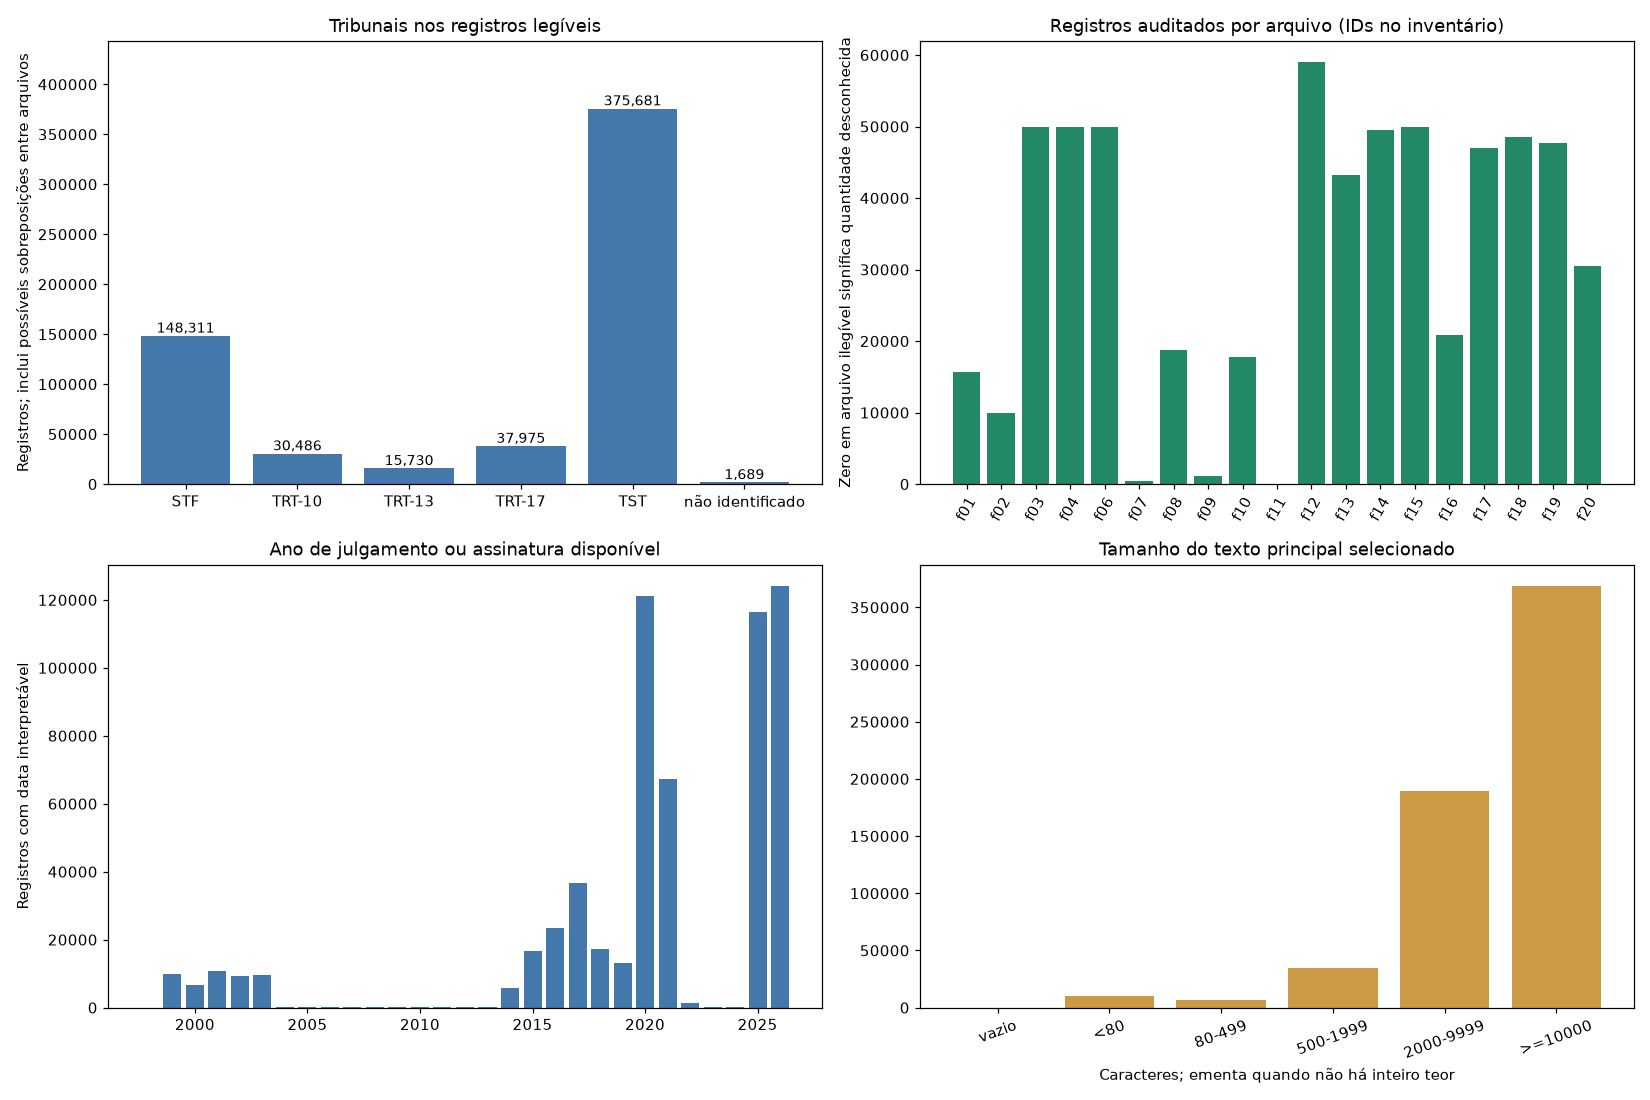

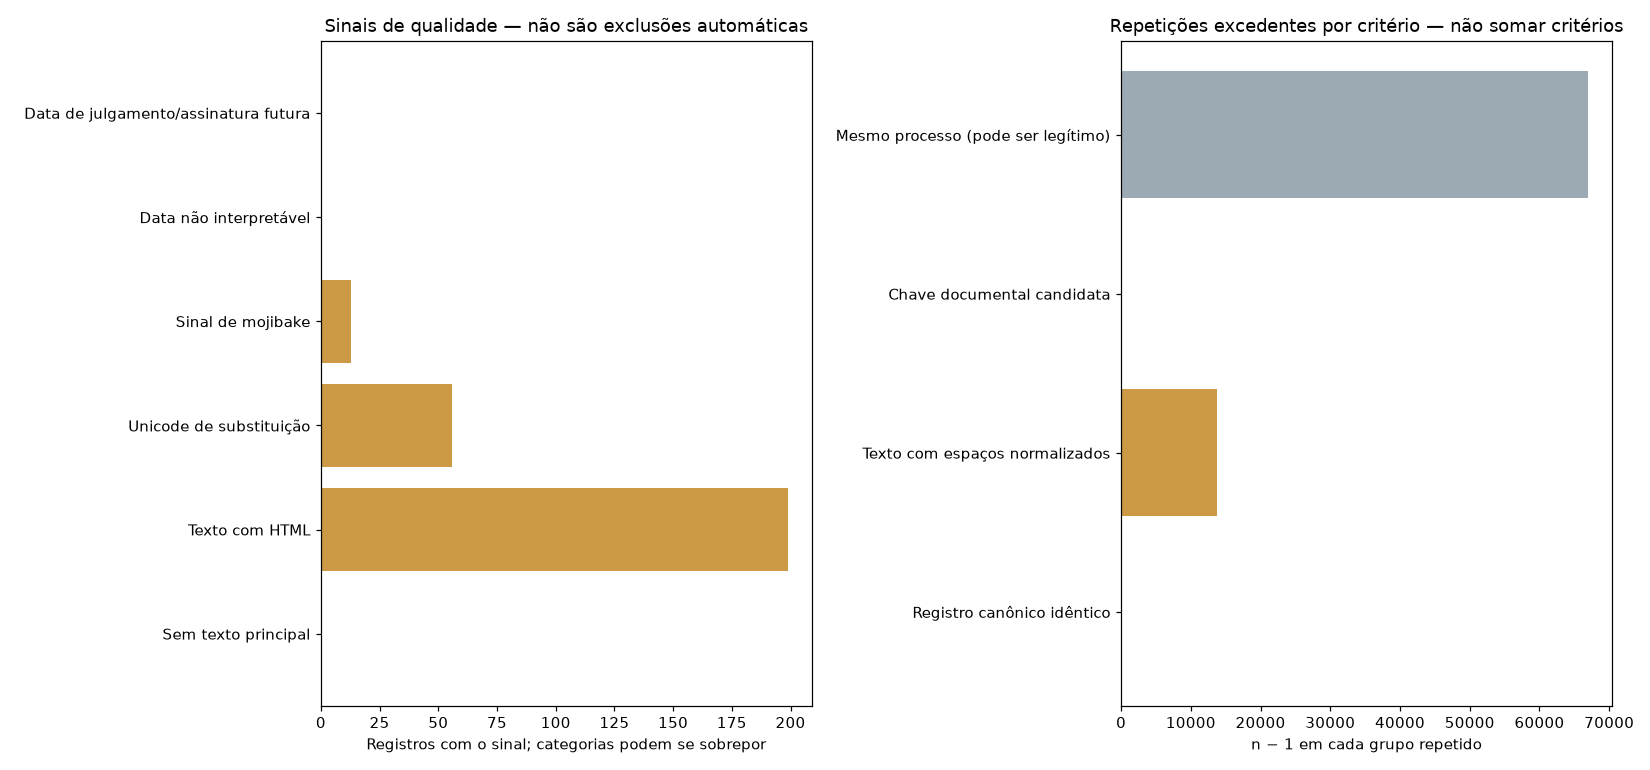

In [9]:
figuras_jur = report.figures(REPORT_JUR_VIEW, resumo_jur, perfis_jur)
plt.show()

## 8. Conclusão atualizada

Os achados da auditoria permanecem no escopo dos registros originais. A conclusão incorpora a estruturação concluída, a revisão do seção de verificação automática e a rastreabilidade verificada no seção de fontes e proveniência. O shard adicional STF permanece fora das contagens.

In [10]:
from src.jurisprudencia import presentation
conclusao_jur = presentation.conclusion(ROOT_JUR, 'auditoria', report.conclusion(REPORT_JUR_VIEW, resumo_jur, perfis_jur))
(REPORT_JUR_VIEW/'conclusao_auditoria_atualizada.md').write_text(conclusao_jur,encoding='utf-8')
display(Markdown(conclusao_jur))


# Conclusão da auditoria de jurisprudência

## Escopo e volume observado

Foram recebidos **19 arquivos**, com **2.76 GiB de bytes originais. A leitura percorreu integralmente **19 arquivos**. Há **0 arquivos ausentes, com erro ou leitura parcial**.

Foram auditados **609,872 registros legíveis**. Após comparar o registro inteiro em JSON canônico, foram observadas **609,872 representações distintas**. Isso não representa uma seleção de decisões jurídicas únicas: registros diferentes podem pertencer ao mesmo processo ou reproduzir o mesmo texto.

Tribunais encontrados nos dados: **STF: 148,311, TRT-10: 30,486, TRT-13: 15,730, TRT-17: 37,975, TST: 375,681, não identificado: 1,689**. A identificação prioriza campos estruturados, incluindo `registro.orgao.sigla` no JSON aninhado do TST. Menções ao STF, TST ou a um TRT no corpo da decisão e o tribunal de origem no número do processo não identificam automaticamente o tribunal julgador. Hipóteses provenientes somente do nome do arquivo ficam identificadas no perfil.

## Integridade e arquivos com problemas

Não houve erro impeditivo na leitura dos arquivos fornecidos. Registros inacessíveis não foram estimados pela quantidade de outros shards. Um arquivo Parquet com assinatura PAR1 pode, ainda assim, ter metadados ou páginas inválidos. Os originais não foram modificados nem reparados silenciosamente.

O escopo ativo inclui somente os arquivos legíveis selecionados; o inventário histórico dos arquivos recebidos foi preservado.

## Esquemas, features e completude

Os esquemas são descritos por arquivo em `inventario_arquivos.csv`, `dicionario_features.csv` e nos perfis JSON. O JSON do TST contém objetos aninhados; features de raiz e caminhos aninhados são contabilizados separadamente para evitar uma comparação enganosa com colunas planas do Parquet.

Ausência da chave, valor nulo e valor vazio são medidos separadamente. Zero e `False` são dados preenchidos. A cardinalidade é exata somente até o limite operacional informado; quando o limite é atingido, a contagem é um limite inferior da amostra inicial, não uma estimativa do total.

Campos com conteúdo JSON armazenado como string, como `data_json` e `metadata_extra_json`, permanecem strings nesta auditoria; seus campos internos exigem uma etapa de estruturação própria. Listas e relações de partes também não são explodidas em novas linhas.

## Qualidade textual e datas

Há **0 registros sem texto principal utilizável** segundo a prioridade de campos documentada; **10,041 textos não vazios com menos de 80 caracteres**, e **199 textos com marcação HTML detectada**. Esses indicadores são triagens e não regras automáticas de exclusão.

O campo de inteiro teor tem prioridade; quando ausente, a ementa pode ser usada como texto disponível. A disponibilidade de ementa não significa que exista inteiro teor. Os gráficos de tamanho incluem todos os registros legíveis e informam explicitamente caracteres, não tokens.

Datas de julgamento e publicação são avaliadas com os campos disponíveis. No TRT-13, `data_assinatura` é usada como alternativa identificada, sem afirmar que seja a data de julgamento. Datas futuras, datas não interpretáveis e publicação anterior ao julgamento/assinatura são alertas para conferência, não provas automáticas de erro jurídico.

Hash de texto declarado que não coincida com candidatos brutos pode resultar de algoritmo ou normalização não documentados. É necessário conferir o produtor antes de concluir que o texto está corrompido.

## Duplicação e risco de vazamento entre avaliações

São separados: registros integralmente idênticos após serialização canônica; textos iguais após normalizar espaços; chaves documentais candidatas repetidas; e múltiplos documentos do mesmo processo. O mesmo processo pode ter várias decisões válidas. As chaves de provedores distintos também podem usar namespaces diferentes. Nenhuma dessas verificações remove registros nesta etapa.

Os relatórios de grupos apresentam somente fingerprints e contagens, sem texto ou número de processo. Antes de dividir desenvolvimento e teste do RAG, revisar sobreposições de texto, documento e processo entre fontes. Os nomes `train` dos arquivos de origem não determinam a partição do nosso experimento.

## Dados pessoais e origem

A triagem detectou **3,281 registros com sequência compatível com CPF de dígitos verificadores válidos** no texto e **776 com candidato a e-mail**. Podem existir falsos positivos e falsos negativos. Há também campos de partes ou contatos que exigem revisão específica. Relatores são agentes públicos identificados na fonte; não devem ser confundidos com partes processuais.

Não foi realizada anonimização. Hashes e fingerprints não garantem anonimato. A varredura considera o texto principal selecionado e campos explicitamente identificados; não substitui análise de todos os objetos e metadados embutidos. O notebook e os relatórios não reproduzem decisões, CPFs ou nomes de partes.

## Síntese e pendências

A auditoria ativa abrange 19 arquivos e os mesmos 609.872 registros legíveis. A origem de 18 dos 19 arquivos ativos foi confirmada por SHA-256 e tamanho; permanece sem correspondência exata `jurisprudencias_tst.json`. O arquivo ilegível foi excluído do escopo ativo por solicitação da pessoa usuária, sem apagar o original. A cópia oficial adicional de 50.000 registros STF está separada e não integra essas contagens.

Os alertas de privacidade e as classificações computacionais estão registrados no [Verificação automática](03_limpeza_estruturacao_jurisprudencia.ipynb#verificacao-automatica); o [Origens e cópia oficial](03_limpeza_estruturacao_jurisprudencia.ipynb#fontes-proveniencia) contém as evidências de proveniência. Os métodos não comprovam mérito jurídico ou anonimização integral.
